In [8]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("CSV files found:")

for file in Path.cwd().rglob("CRMLSSold*.csv"):
    print(file)

possible_dirs = [
    Path('upload'),
    Path('../upload'),
    Path('data'),
    Path('data/raw'),
    Path('../data'),
    Path('../data/raw'),
    Path('.'),
    Path('..')
]

Current folder: /Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks
CSV files found:
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202409.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202501_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold20220101_20231231_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202406_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202412.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202407_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202411.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202410.csv


Week 2 — Exploratory Data Analysis

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Search everywhere inside the current project folder
files = sorted(Path.cwd().rglob("CRMLSSold*.csv"))

# Ignore the combined 2022–2023 file
files = [
    file for file in files
    if "20220101_20231231" not in file.name
]

if not files:
    raise FileNotFoundError(
        "No CRMLSSold CSV files were found in the project folder."
    )

print("Files found:")
for file in files:
    print(file)

# Load each CSV file
frames = []

for file in files:
    temp = pd.read_csv(file, low_memory=False)
    temp["source_file"] = file.name
    frames.append(temp)

# Combine all monthly files
df = pd.concat(frames, ignore_index=True, sort=False)

# Convert the closing date into a date format
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

print("Raw shape:", df.shape)

Files found:
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202406_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202407_filled.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202409.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202410.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202411.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202412.csv
/Users/alexphan/Documents/GitHub/IDX-Exchange-Data-Science/notebooks/data/CRMLSSold202501_filled.csv
Raw shape: (154367, 81)


In [2]:
# Keep only the property types required by the project instructions.
df = df[(df['PropertyType'] == 'Residential') &
        (df['PropertySubType'] == 'SingleFamilyResidence')].copy()
# Convert the main analysis columns to numbers so statistics and plots work correctly.
for col in ['ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df[df['ClosePrice'].notna() & (df['ClosePrice'] > 0)].copy()
df['CloseMonth'] = df['CloseDate'].dt.to_period('M').astype(str)
print('Filtered shape:', df.shape)
display(df[['ClosePrice','LivingArea','BedroomsTotal','BathroomsTotalInteger','LotSizeSquareFeet']].describe().T)

Filtered shape: (78637, 82)


,count,mean,std,min,25%,50%,75%,max
ClosePrice,78637.0,1.267321e+06,1.541329e+06,1.15,630000.0,900000.0,1450000.0,1.425900e+08
LivingArea,78593.0,2.023322e+03,1.126383e+03,0.00,1370.0,1788.0,2400.0,1.237640e+05
BedroomsTotal,78637.0,3.476417e+00,9.538642e-01,0.00,3.0,3.0,4.0,3.400000e+01
BathroomsTotalInteger,78622.0,2.602185e+00,1.243170e+00,0.00,2.0,2.0,3.0,1.530000e+02
LotSizeSquareFeet,77315.0,1.749504e+05,1.063483e+07,0.00,5663.0,7200.0,10147.5,1.897474e+09


Missing values in the main analysis columns

In [3]:
main_cols = ['ClosePrice', 'LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet']
missing = df[main_cols].isna().sum().to_frame('missing_count')
missing['missing_percent'] = (missing['missing_count'] / len(df) * 100).round(2)
display(missing)

,missing_count,missing_percent
ClosePrice,0,0.00
LivingArea,44,0.06
BedroomsTotal,0,0.00
BathroomsTotalInteger,15,0.02
LotSizeSquareFeet,1322,1.68


Distributions

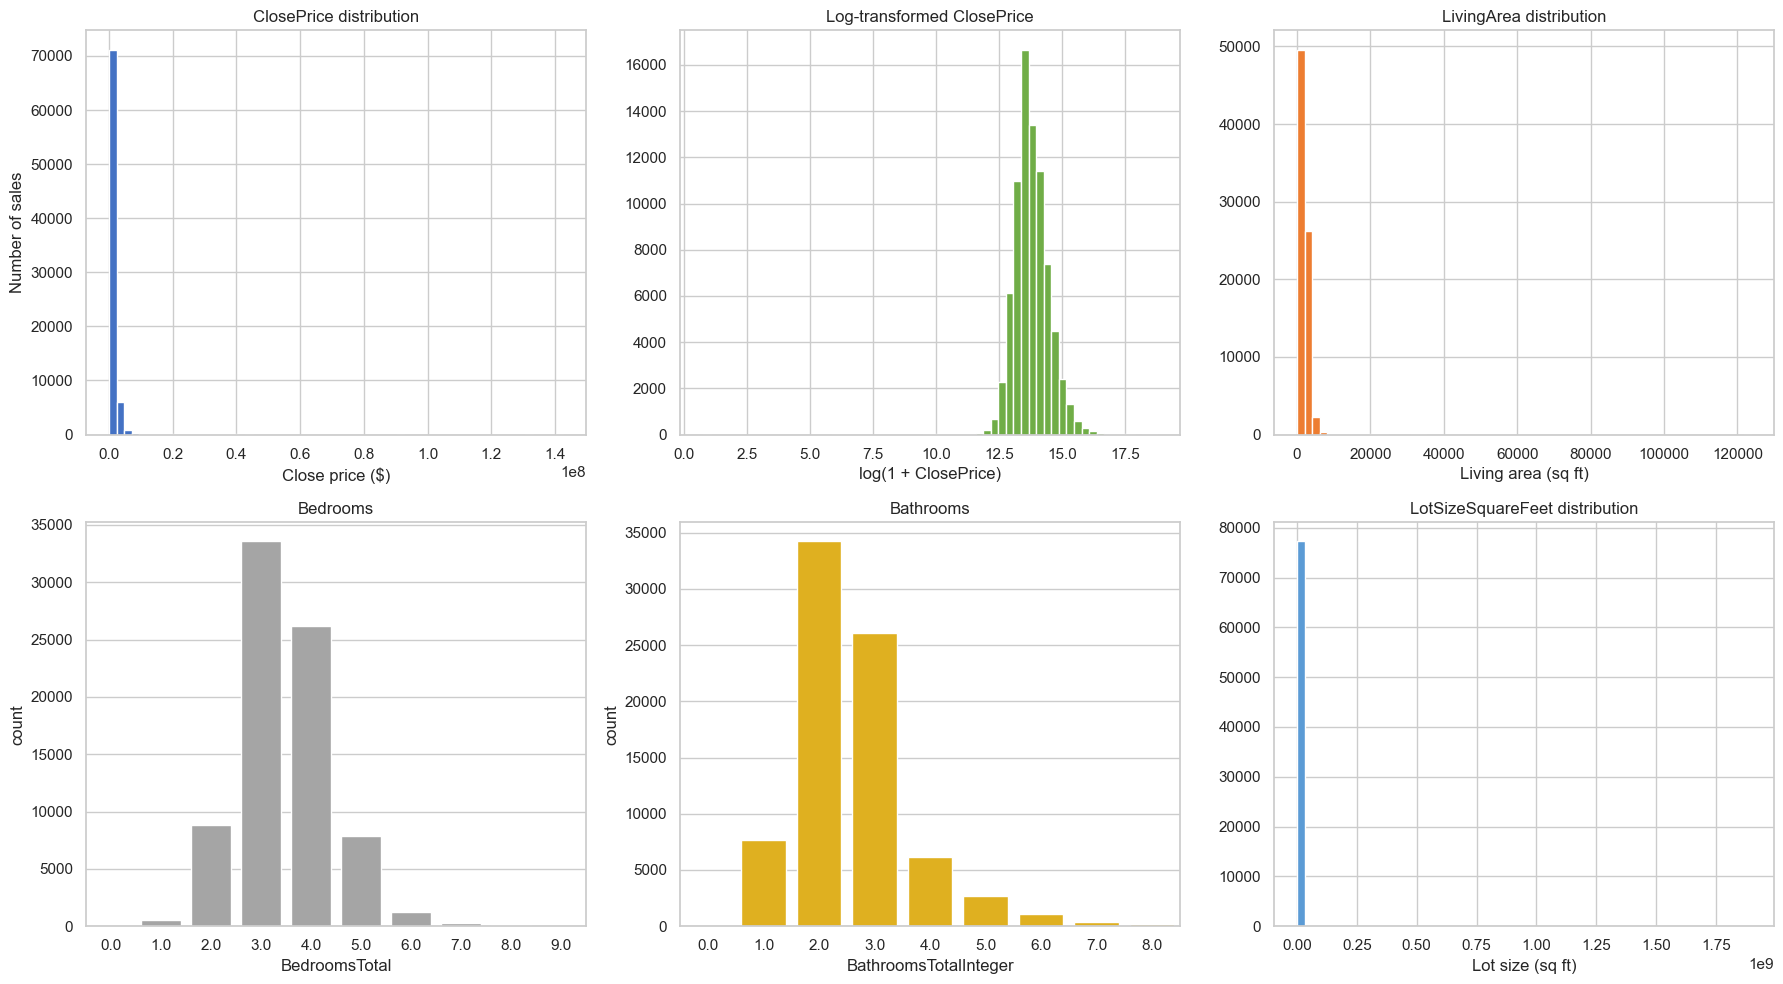

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].hist(df['ClosePrice'].dropna(), bins=60, color='#4472C4')
axes[0, 0].set_title('ClosePrice distribution')
axes[0, 0].set_xlabel('Close price ($)')
axes[0, 0].set_ylabel('Number of sales')
axes[0, 1].hist(np.log1p(df['ClosePrice'].dropna()), bins=60, color='#70AD47')
axes[0, 1].set_title('Log-transformed ClosePrice')
axes[0, 1].set_xlabel('log(1 + ClosePrice)')
axes[0, 2].hist(df['LivingArea'].dropna(), bins=60, color='#ED7D31')
axes[0, 2].set_title('LivingArea distribution')
axes[0, 2].set_xlabel('Living area (sq ft)')

sns.countplot(data=df, x='BedroomsTotal', ax=axes[1, 0], color='#A5A5A5')
axes[1, 0].set_title('Bedrooms')
axes[1, 0].set_xlim(-0.5, 9.5)
sns.countplot(data=df, x='BathroomsTotalInteger', ax=axes[1, 1], color='#FFC000')
axes[1, 1].set_title('Bathrooms')
axes[1, 1].set_xlim(-0.5, 8.5)
axes[1, 2].hist(df['LotSizeSquareFeet'].dropna(), bins=60, color='#5B9BD5')
axes[1, 2].set_title('LotSizeSquareFeet distribution')
axes[1, 2].set_xlabel('Lot size (sq ft)')
plt.tight_layout()

Relationships with final sale price

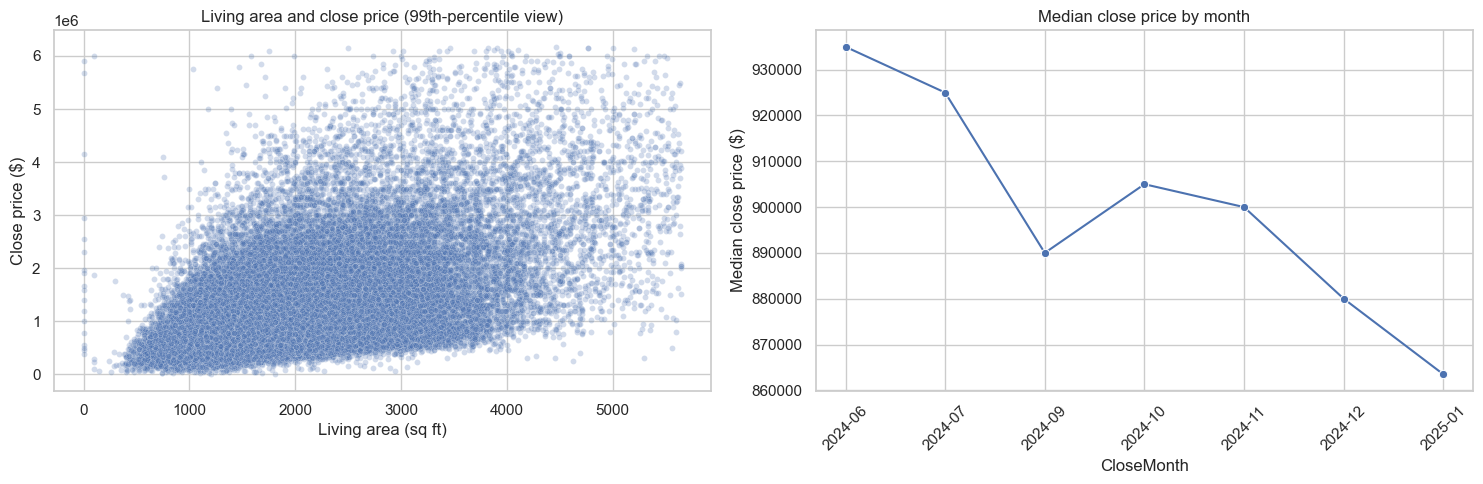

In [6]:
plot_df = df[(df['ClosePrice'] <= df['ClosePrice'].quantile(.99)) &
              (df['LivingArea'] <= df['LivingArea'].quantile(.99))].copy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=plot_df, x='LivingArea', y='ClosePrice', alpha=.25, s=18, ax=axes[0])
axes[0].set_title('Living area and close price (99th-percentile view)')
axes[0].set_xlabel('Living area (sq ft)')
axes[0].set_ylabel('Close price ($)')
monthly = df.groupby('CloseMonth', as_index=False)['ClosePrice'].median()
sns.lineplot(data=monthly, x='CloseMonth', y='ClosePrice', marker='o', ax=axes[1])
axes[1].set_title('Median close price by month')
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylabel('Median close price ($)')
plt.tight_layout()

Initial observations:
The raw ClosePrice distribution is strongly right-skewed, so the log-transformed view is useful for visual interpretation. Living area generally has a positive relationship with sale price, but the spread shows that location and other property characteristics also matter. The preprocessing step will handle missing numeric values and encode selected geographic categorical variables.